In [2]:
import pandas as pd

In [33]:
df_in = pd.read_excel('Online Retail.xlsx')

In [4]:
df_in

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


In [11]:
import pandasql as psql

# Tabla productos (por StockCode)
productos = psql.sqldf("""
    SELECT DISTINCT StockCode, Description, UnitPrice

    FROM df_in
""")

# Tabla boletas (por InvoiceNo)
boletas = psql.sqldf("""
    SELECT DISTINCT InvoiceNo, InvoiceDate, CustomerID, Country

    FROM df_in
""")

# Tabla países (por Country)
paises = psql.sqldf("""
    SELECT DISTINCT Country

    FROM df_in
""")

PendingRollbackError: Can't reconnect until invalid transaction is rolled back.  Please rollback() fully before proceeding (Background on this error at: https://sqlalche.me/e/20/8s2b)

In [ ]:
psql.sqldf("""
    SELECT
        InvoiceDate,
        julianday(InvoiceDate) -   as recencia

    FROM df_in
    WHERE CustomerID IS NOT NULL
""")

,InvoiceDate,recencia
0,2010-12-01 08:26:00.000000,-372.648611
1,2010-12-01 08:26:00.000000,-372.648611
2,2010-12-01 08:26:00.000000,-372.648611
3,2010-12-01 08:26:00.000000,-372.648611
4,2010-12-01 08:26:00.000000,-372.648611
...,...,...
406824,2011-12-09 12:50:00.000000,0.534722
406825,2011-12-09 12:50:00.000000,0.534722
406826,2011-12-09 12:50:00.000000,0.534722
406827,2011-12-09 12:50:00.000000,0.534722


In [52]:
# Tabla clientes (por CustomerID)
clientes_1 = psql.sqldf("""
    SELECT DISTINCT
        CustomerID, Country,
        max(InvoiceDate) as ultima_compra,
        julianday('2011-12-10') - julianday(max(InvoiceDate)) as recencia,
        min(InvoiceDate) as primera_compra,
        julianday(max(InvoiceDate)) - julianday(min(InvoiceDate)) as antiguedad,
        count(distinct InvoiceDate) as n_dias_compra,
        count(distinct InvoiceDate) / (julianday(max(InvoiceDate)) - julianday(min(InvoiceDate))) as frequency,
        count(distinct InvoiceNo) as n_boletas,
        sum(Quantity) as n_items,
        sum(Quantity * UnitPrice) as ventas,
        avg(Quantity * UnitPrice) as ticket_promedio,
        avg(Quantity) as items_promedio,
        sum(Quantity * UnitPrice) / sum(Quantity) as avg_item_price
    FROM df_in
    WHERE CustomerID IS NOT NULL and Description != 'Manual'
    group by CustomerID, country
""")

In [53]:
clientes_1.sort_values(by='ventas', ascending=False)

,CustomerID,Country,ultima_compra,recencia,primera_compra,antiguedad,n_dias_compra,frequency,n_boletas,n_items,ventas,ticket_promedio,items_promedio,avg_item_price
1708,14646.0,Netherlands,2011-12-08 12:12:00.000000,1.491667,2010-12-20 10:09:00.000000,353.085417,77,0.218078,77,197199,279594.62,134.162486,94.625240,1.417830
4232,18102.0,United Kingdom,2011-12-09 11:50:00.000000,0.506944,2010-12-07 16:42:00.000000,366.797222,55,0.149947,60,64124,259657.30,602.453132,148.779582,4.049300
3758,17450.0,United Kingdom,2011-12-01 13:29:00.000000,8.438194,2010-12-07 09:23:00.000000,359.170833,54,0.150346,54,69034,188712.33,543.839568,198.945245,2.733614
1900,14911.0,EIRE,2011-12-08 15:54:00.000000,1.337500,2010-12-01 14:05:00.000000,372.075694,244,0.655781,244,77180,132572.62,22.473745,13.083573,1.717707
57,12415.0,Australia,2011-11-15 14:22:00.000000,24.401389,2011-01-06 11:12:00.000000,313.131944,25,0.079839,26,77242,123725.45,159.030141,99.282776,1.601790
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
270,12666.0,Israel,2010-12-15 14:42:00.000000,359.387500,2010-12-15 14:42:00.000000,0.000000,1,NaN,1,-56,-227.44,-113.720000,-28.000000,4.061429
2894,16252.0,United Kingdom,2010-12-08 16:15:00.000000,366.322917,2010-12-08 16:15:00.000000,0.000000,1,NaN,1,-158,-295.09,-14.051905,-7.523810,1.867658
3247,16742.0,United Kingdom,2011-10-24 11:58:00.000000,46.501389,2011-10-24 11:58:00.000000,0.000000,1,NaN,1,-190,-464.90,-154.966667,-63.333333,2.446842
2580,15823.0,United Kingdom,2011-01-06 12:58:00.000000,337.459722,2010-12-02 15:08:00.000000,34.909722,2,0.057291,2,-281,-796.86,-49.803750,-17.562500,2.835801


In [54]:
# Tabla clientes (por CustomerID)
clientes_2 = psql.sqldf("""
    SELECT *
    FROM clientes_1
    WHERE ventas > 0
""")

In [64]:
new_df = psql.sqldf(""" select * from df_in where CustomerID in (select distinct CustomerID from clientes_2) """)

## ANALISIS POR PRODUCTO

In [65]:
product_df = psql.sqldf("""
select distinct
                        Description,
                        sum(Quantity) as items,
                        sum(Quantity * UnitPrice) as ventas,
                        avg(Quantity * UnitPrice) as ticket_promedio,
                        avg(Quantity) as items_promedio,
                        sum(Quantity * UnitPrice) / sum(Quantity) as avg_item_price
from df_in
where Description != 'Manual'
group by Description, UnitPrice
""")




,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00.000000,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00.000000,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00.000000,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00.000000,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00.000000,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
406290,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00.000000,0.85,12680.0,France
406291,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00.000000,2.10,12680.0,France
406292,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00.000000,4.15,12680.0,France
406293,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00.000000,4.15,12680.0,France


In [57]:
clientes_2.sort_values(by='ventas', ascending=False)

,CustomerID,Country,ultima_compra,recencia,primera_compra,antiguedad,n_dias_compra,frequency,n_boletas,n_items,ventas,ticket_promedio,items_promedio,avg_item_price
1689,14646.0,Netherlands,2011-12-08 12:12:00.000000,1.491667,2010-12-20 10:09:00.000000,353.085417,77,0.218078,77,197199,279594.62,134.162486,94.625240,1.417830
4193,18102.0,United Kingdom,2011-12-09 11:50:00.000000,0.506944,2010-12-07 16:42:00.000000,366.797222,55,0.149947,60,64124,259657.30,602.453132,148.779582,4.049300
3722,17450.0,United Kingdom,2011-12-01 13:29:00.000000,8.438194,2010-12-07 09:23:00.000000,359.170833,54,0.150346,54,69034,188712.33,543.839568,198.945245,2.733614
1878,14911.0,EIRE,2011-12-08 15:54:00.000000,1.337500,2010-12-01 14:05:00.000000,372.075694,244,0.655781,244,77180,132572.62,22.473745,13.083573,1.717707
56,12415.0,Australia,2011-11-15 14:22:00.000000,24.401389,2011-01-06 11:12:00.000000,313.131944,25,0.079839,26,77242,123725.45,159.030141,99.282776,1.601790
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4090,17956.0,United Kingdom,2011-04-04 13:47:00.000000,249.425694,2011-04-04 13:47:00.000000,0.000000,1,NaN,1,1,12.75,12.750000,1.000000,12.750000
4170,18072.0,United Kingdom,2011-07-07 17:22:00.000000,155.276389,2011-06-07 10:44:00.000000,30.276389,2,0.066058,2,48,12.24,0.360000,1.411765,0.255000
3011,16454.0,United Kingdom,2011-10-06 16:57:00.000000,64.293750,2011-10-06 16:57:00.000000,0.000000,1,NaN,1,2,5.90,5.900000,2.000000,2.950000
3213,16738.0,United Kingdom,2011-02-15 09:46:00.000000,297.593056,2011-02-15 09:46:00.000000,0.000000,1,NaN,1,3,3.75,3.750000,3.000000,1.250000


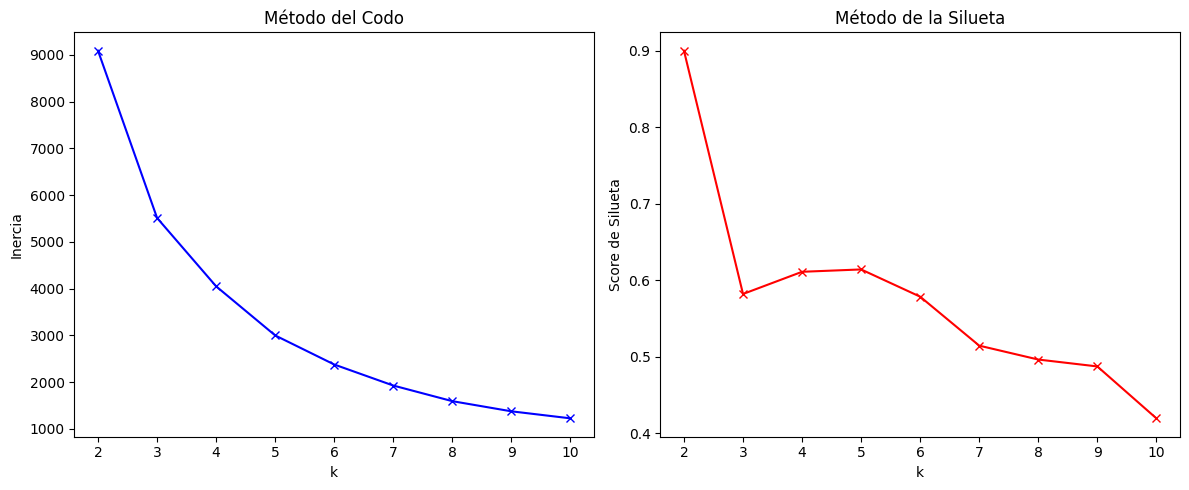


Estadísticas por Cluster:
              R              F                 M           CustomerID
           mean    std    mean    std       mean       std      count
Cluster                                                              
0         39.57  34.62    5.68   6.96    1947.60   3903.43       3225
1        243.53  67.65    1.85   1.72     527.79   1489.69       1089
2          6.91  11.13  103.07  66.57  107630.98  83016.81         14


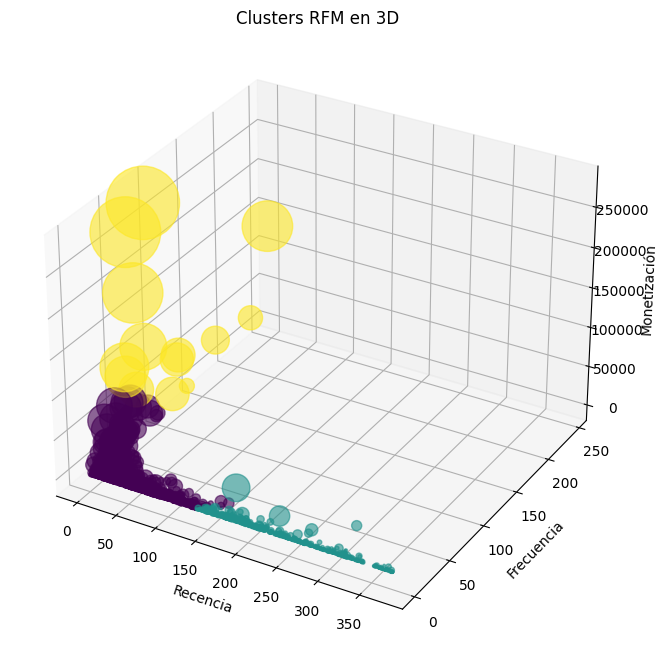

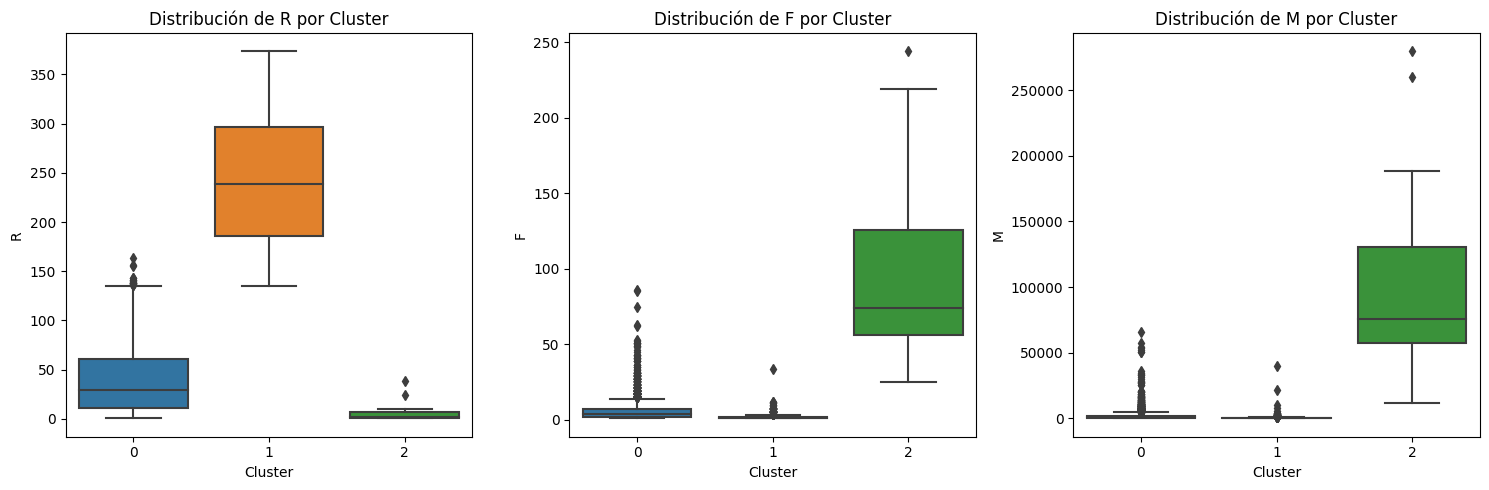


Distribución de Segmentos:
Segmento
Clientes de Alto Valor    3225
Clientes Leales           1089
Clientes en Riesgo          14
Name: count, dtype: int64

Estadísticas por Segmento:
                             R       F          M  CustomerID
Segmento                                                     
Clientes Leales         243.53    1.85     527.79        1089
Clientes de Alto Valor   39.57    5.68    1947.60        3225
Clientes en Riesgo        6.91  103.07  107630.98          14


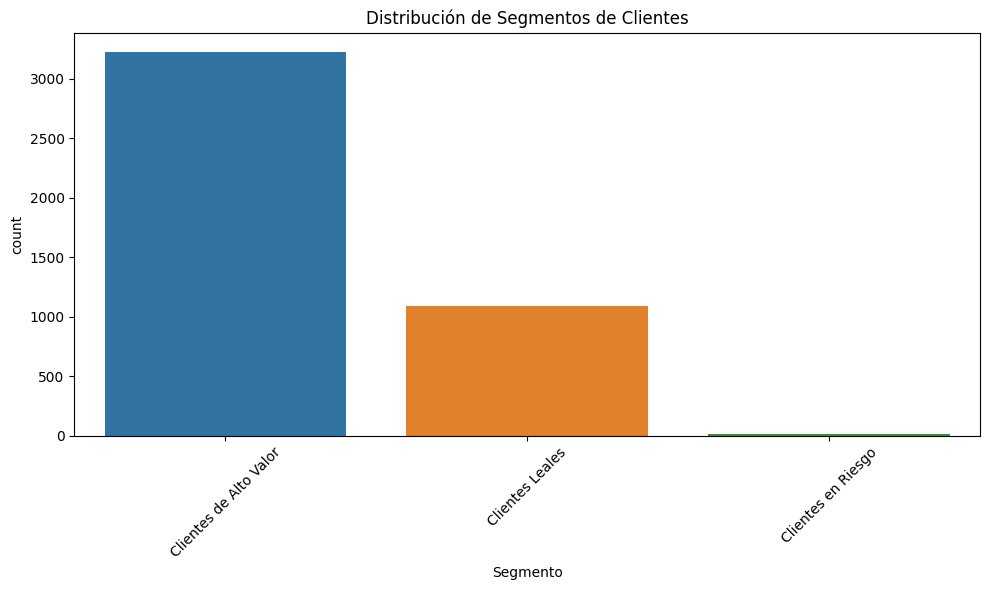

In [60]:
import pandas as pd
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')

# Convertir la columna de última compra a datetime
df['ultima_compra'] = pd.to_datetime(df['ultima_compra'])

# Calcular la fecha de referencia (última fecha de compra en el dataset)
fecha_referencia = df['ultima_compra'].max()

# Calcular Recencia (R)
df['R'] = df['recencia']

# Usar n_dias_compra para Frecuencia (F)
df['F'] = df['n_dias_compra']

# Usar ventas para Monetización (M)
df['M'] = df['ventas']

# Seleccionar las variables RFM para el clustering
rfm_data = df[['R', 'F', 'M']]

# Estandarizar los datos
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_data)

# Método del codo para determinar el número óptimo de clusters
inertias = []
silhouette_scores = []
K = range(2, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(rfm_scaled, kmeans.labels_))

# Graficar el método del codo y score de silueta
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(K, inertias, 'bx-')
plt.xlabel('k')
plt.ylabel('Inercia')
plt.title('Método del Codo')

plt.subplot(1, 2, 2)
plt.plot(K, silhouette_scores, 'rx-')
plt.xlabel('k')
plt.ylabel('Score de Silueta')
plt.title('Método de la Silueta')
plt.tight_layout()
plt.show()

# Determinar el número óptimo de clusters (ajusta este valor según los gráficos)
k_optimo = 3

# Aplicar K-means con el número óptimo de clusters
kmeans = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(rfm_scaled)

# Calcular las estadísticas de cada cluster
cluster_stats = df.groupby('Cluster').agg({
    'R': ['mean', 'std'],
    'F': ['mean', 'std'],
    'M': ['mean', 'std'],
    'CustomerID': 'count'
}).round(2)

print("\nEstadísticas por Cluster:")
print(cluster_stats)

# Visualizar los clusters en 3D
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(df['R'], df['F'], df['M'], 
                    c=df['Cluster'], cmap='viridis',
                    s=df['M']/100, alpha=0.6)

ax.set_xlabel('Recencia')
ax.set_ylabel('Frecuencia')
ax.set_zlabel('Monetización')
plt.title('Clusters RFM en 3D')
plt.show()

# Visualizar la distribución de cada métrica RFM por cluster
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, metric in enumerate(['R', 'F', 'M']):
    sns.boxplot(x='Cluster', y=metric, data=df, ax=axes[i])
    axes[i].set_title(f'Distribución de {metric} por Cluster')
plt.tight_layout()
plt.show()

# Asignar nombres descriptivos a los clusters basados en sus características
def asignar_nombre_cluster(row):
    cluster = row['Cluster']
    r = row['R']
    f = row['F']
    m = row['M']
    
    if cluster == 0:  # Ajusta estos valores según tus resultados
        return 'Clientes de Alto Valor'
    elif cluster == 1:
        return 'Clientes Leales'
    elif cluster == 2:
        return 'Clientes en Riesgo'
    elif cluster == 3:
        return 'Clientes Nuevos'
    else:
        return 'Clientes Ocasionales'

df['Segmento'] = df.apply(asignar_nombre_cluster, axis=1)

# Mostrar la distribución de segmentos
print("\nDistribución de Segmentos:")
print(df['Segmento'].value_counts())

# Guardar resultados
df.to_csv('resultados_rfm_clustering.csv', index=False)

# Análisis adicional por segmento
print("\nEstadísticas por Segmento:")
segmento_stats = df.groupby('Segmento').agg({
    'R': 'mean',
    'F': 'mean',
    'M': 'mean',
    'CustomerID': 'count'
}).round(2)
print(segmento_stats)

# Visualizar la distribución de segmentos
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='Segmento')
plt.xticks(rotation=45)
plt.title('Distribución de Segmentos de Clientes')
plt.tight_layout()
plt.show()

In [26]:
new_df = pd.merge(df, clientes_2, on='CustomerID', how='inner')


In [27]:
new_df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country_x,Country_y,ultima_compra,primera_compra,antiguedad,n_dias_compra,frequency,n_boletas,n_items,ventas,ticket_promedio,items_promedio,avg_item_price
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,United Kingdom,2011-02-10 14:38:00.000000,2010-12-01 08:26:00.000000,71.258333,34,0.477137,35,1693,5288.63,16.950737,5.426282,3.123822
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,United Kingdom,2011-02-10 14:38:00.000000,2010-12-01 08:26:00.000000,71.258333,34,0.477137,35,1693,5288.63,16.950737,5.426282,3.123822
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,United Kingdom,2011-02-10 14:38:00.000000,2010-12-01 08:26:00.000000,71.258333,34,0.477137,35,1693,5288.63,16.950737,5.426282,3.123822
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,United Kingdom,2011-02-10 14:38:00.000000,2010-12-01 08:26:00.000000,71.258333,34,0.477137,35,1693,5288.63,16.950737,5.426282,3.123822
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,United Kingdom,2011-02-10 14:38:00.000000,2010-12-01 08:26:00.000000,71.258333,34,0.477137,35,1693,5288.63,16.950737,5.426282,3.123822
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
407157,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,France,2011-12-09 12:50:00.000000,2011-08-18 15:44:00.000000,112.879167,4,0.035436,4,443,862.81,16.592500,8.519231,1.947652
407158,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,France,2011-12-09 12:50:00.000000,2011-08-18 15:44:00.000000,112.879167,4,0.035436,4,443,862.81,16.592500,8.519231,1.947652
407159,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,France,2011-12-09 12:50:00.000000,2011-08-18 15:44:00.000000,112.879167,4,0.035436,4,443,862.81,16.592500,8.519231,1.947652
407160,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,France,2011-12-09 12:50:00.000000,2011-08-18 15:44:00.000000,112.879167,4,0.035436,4,443,862.81,16.592500,8.519231,1.947652
